In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully.")


Libraries imported successfully.


In [2]:
file_path = "../data/processed/indian_basket_crude_processed.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully.")
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

Dataset loaded successfully.
Shape: (299, 19)

Columns:
['date', 'crude_oil_price', 'previous_crude_price', 'crude_price_change', 'crude_return', 'log_return', 'crude_ma_3', 'crude_ma_6', 'crude_ma_12', 'volatility_3m', 'volatility_6m', 'volatility_12m', 'momentum_3m', 'momentum_6m', 'price_vs_ma_3', 'price_vs_ma_6', 'price_vs_ma_12', 'target_next_month_crude_price', 'target_next_month_change']


In [3]:
print("First 5 rows:")
display(df.head())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

First 5 rows:


,date,crude_oil_price,previous_crude_price,crude_price_change,crude_return,log_return,crude_ma_3,crude_ma_6,crude_ma_12,volatility_3m,volatility_6m,volatility_12m,momentum_3m,momentum_6m,price_vs_ma_3,price_vs_ma_6,price_vs_ma_12,target_next_month_crude_price,target_next_month_change
0,2001-04-01,24.82,23.82,1.00,0.041982,0.041124,24.853333,25.459437,27.106289,0.083810,0.120968,0.108141,0.033306,-0.186230,-0.001341,-0.025116,-0.084345,26.95,2.13
1,2001-05-01,26.95,24.82,2.13,0.085818,0.082334,25.196667,24.796667,27.135456,0.086492,0.129098,0.097652,0.039738,-0.128582,0.069586,0.086840,-0.006834,26.63,-0.32
2,2001-06-01,26.63,26.95,-0.32,-0.011874,-0.011945,26.133333,25.360000,26.980456,0.048931,0.062575,0.095538,0.117968,0.145376,0.019005,0.050079,-0.012989,23.99,-2.64
3,2001-07-01,23.99,26.63,-2.64,-0.099136,-0.104401,25.856667,25.355000,26.707956,0.092526,0.079850,0.099085,-0.033441,-0.001249,-0.072193,-0.053836,-0.101766,25.01,1.02
4,2001-08-01,25.01,23.99,1.02,0.042518,0.041639,25.210000,25.203333,26.431385,0.071460,0.074013,0.099226,-0.071985,-0.035108,-0.007933,-0.007671,-0.053776,24.79,-0.22



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 299 entries, 0 to 298
Data columns (total 19 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   date                           299 non-null    object 
 1   crude_oil_price                299 non-null    float64
 2   previous_crude_price           299 non-null    float64
 3   crude_price_change             299 non-null    float64
 4   crude_return                   299 non-null    float64
 5   log_return                     299 non-null    float64
 6   crude_ma_3                     299 non-null    float64
 7   crude_ma_6                     299 non-null    float64
 8   crude_ma_12                    299 non-null    float64
 9   volatility_3m                  299 non-null    float64
 10  volatility_6m                  299 non-null    float64
 11  volatility_12m                 299 non-null    float64
 12  momentum_3m                 

In [4]:
df["date"] = pd.to_datetime(df["date"], errors="coerce")

df = df.sort_values("date").reset_index(drop=True)

print("Date conversion completed.")
print("Start date:", df["date"].min())
print("End date:", df["date"].max())

Date conversion completed.
Start date: 2001-04-01 00:00:00
End date: 2026-02-01 00:00:00


In [5]:
features = [
    "previous_crude_price",
    "crude_price_change",
    "crude_return",
    "log_return",
    "crude_ma_3",
    "crude_ma_6",
    "crude_ma_12",
    "volatility_3m",
    "volatility_6m",
    "volatility_12m",
    "momentum_3m",
    "momentum_6m",
    "price_vs_ma_3",
    "price_vs_ma_6",
    "price_vs_ma_12"
]

target = "target_next_month_crude_price"

features = [col for col in features if col in df.columns]

print("Features used:")
print(features)

print("\nTarget:")
print(target)

Features used:
['previous_crude_price', 'crude_price_change', 'crude_return', 'log_return', 'crude_ma_3', 'crude_ma_6', 'crude_ma_12', 'volatility_3m', 'volatility_6m', 'volatility_12m', 'momentum_3m', 'momentum_6m', 'price_vs_ma_3', 'price_vs_ma_6', 'price_vs_ma_12']

Target:
target_next_month_crude_price


In [6]:
model_df = df[["date"] + features + [target]].copy()

model_df = model_df.dropna().reset_index(drop=True)

print("Model dataset shape:", model_df.shape)
display(model_df.head())

Model dataset shape: (299, 17)


,date,previous_crude_price,crude_price_change,crude_return,log_return,crude_ma_3,crude_ma_6,crude_ma_12,volatility_3m,volatility_6m,volatility_12m,momentum_3m,momentum_6m,price_vs_ma_3,price_vs_ma_6,price_vs_ma_12,target_next_month_crude_price
0,2001-04-01,23.82,1.00,0.041982,0.041124,24.853333,25.459437,27.106289,0.083810,0.120968,0.108141,0.033306,-0.186230,-0.001341,-0.025116,-0.084345,26.95
1,2001-05-01,24.82,2.13,0.085818,0.082334,25.196667,24.796667,27.135456,0.086492,0.129098,0.097652,0.039738,-0.128582,0.069586,0.086840,-0.006834,26.63
2,2001-06-01,26.95,-0.32,-0.011874,-0.011945,26.133333,25.360000,26.980456,0.048931,0.062575,0.095538,0.117968,0.145376,0.019005,0.050079,-0.012989,23.99
3,2001-07-01,26.63,-2.64,-0.099136,-0.104401,25.856667,25.355000,26.707956,0.092526,0.079850,0.099085,-0.033441,-0.001249,-0.072193,-0.053836,-0.101766,25.01
4,2001-08-01,23.99,1.02,0.042518,0.041639,25.210000,25.203333,26.431385,0.071460,0.074013,0.099226,-0.071985,-0.035108,-0.007933,-0.007671,-0.053776,24.79


In [7]:
print("Target statistics:")
print(model_df[target].describe())

print("\nTarget missing values:")
print(model_df[target].isnull().sum())

Target statistics:
count    299.000000
mean      67.747059
std       26.981305
min       18.240000
25%       46.979168
50%       66.953085
75%       84.371291
max      132.471248
Name: target_next_month_crude_price, dtype: float64

Target missing values:
0


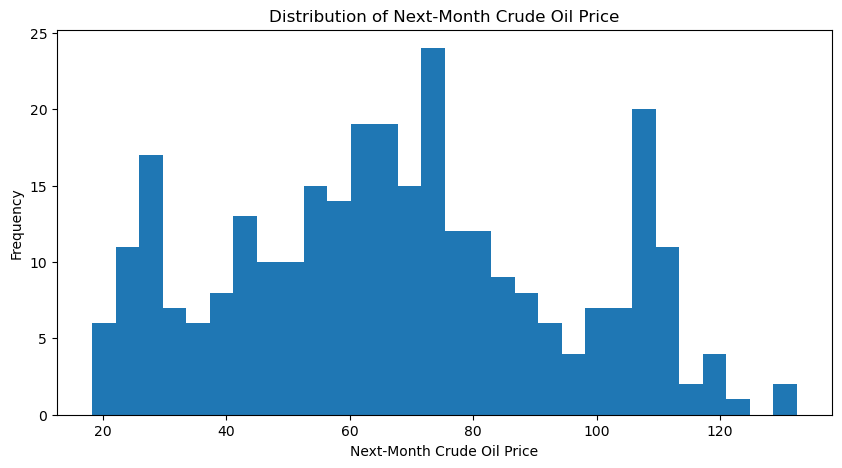

In [8]:
plt.figure(figsize=(10, 5))

plt.hist(model_df[target], bins=30)

plt.title("Distribution of Next-Month Crude Oil Price")
plt.xlabel("Next-Month Crude Oil Price")
plt.ylabel("Frequency")

plt.show()

In [9]:
split_index = int(len(model_df) * 0.80)

train_df = model_df.iloc[:split_index].copy()
test_df = model_df.iloc[split_index:].copy()

print("Training samples:", len(train_df))
print("Testing samples:", len(test_df))

print("\nTraining period:")
print(train_df["date"].min(), "to", train_df["date"].max())

print("\nTesting period:")
print(test_df["date"].min(), "to", test_df["date"].max())

Training samples: 239
Testing samples: 60

Training period:
2001-04-01 00:00:00 to 2021-02-01 00:00:00

Testing period:
2021-03-01 00:00:00 to 2026-02-01 00:00:00


In [10]:
X_train = train_df[features]
y_train = train_df[target]

X_test = test_df[features]
y_test = test_df[target]

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (239, 15)
X_test shape: (60, 15)
y_train shape: (239,)
y_test shape: (60,)


In [11]:
baseline_prediction = y_train.mean()

baseline_pred = np.full(
    len(y_test),
    baseline_prediction
)

baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_pred))

print("Baseline Mean Prediction:", baseline_prediction)
print("Baseline MAE:", baseline_mae)
print("Baseline RMSE:", baseline_rmse)

Baseline Mean Prediction: 64.46392327352356
Baseline MAE: 16.537258161957944
Baseline RMSE: 20.79929202169042


In [12]:
linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

linear_pred = linear_model.predict(X_test)

print("Linear Regression training completed.")

Linear Regression training completed.


In [13]:
linear_mae = mean_absolute_error(y_test, linear_pred)
linear_rmse = np.sqrt(mean_squared_error(y_test, linear_pred))

print("Linear Regression MAE:", linear_mae)
print("Linear Regression RMSE:", linear_rmse)

Linear Regression MAE: 5.610043266278449
Linear Regression RMSE: 8.268037423383909


In [14]:
coefficients = pd.DataFrame({
    "feature": features,
    "coefficient": linear_model.coef_
})

coefficients = coefficients.sort_values(
    "coefficient",
    key=abs,
    ascending=False
)

display(coefficients)

,feature,coefficient
12,price_vs_ma_3,-28.507974
9,volatility_12m,9.700968
14,price_vs_ma_12,6.697052
2,crude_return,-5.994959
10,momentum_3m,-3.658264
3,log_return,2.937526
13,price_vs_ma_6,-2.921067
1,crude_price_change,2.009419
7,volatility_3m,-1.942056
0,previous_crude_price,1.670733


In [15]:
rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

print("Random Forest training completed.")

Random Forest training completed.


In [16]:
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))

print("Random Forest MAE:", rf_mae)
print("Random Forest RMSE:", rf_rmse)

Random Forest MAE: 6.178303183109208
Random Forest RMSE: 8.902504657089143


In [17]:
results = pd.DataFrame({
    "Model": [
        "Baseline",
        "Linear Regression",
        "Random Forest"
    ],
    "MAE": [
        baseline_mae,
        linear_mae,
        rf_mae
    ],
    "RMSE": [
        baseline_rmse,
        linear_rmse,
        rf_rmse
    ]
})

display(results)

,Model,MAE,RMSE
0,Baseline,16.537258,20.799292
1,Linear Regression,5.610043,8.268037
2,Random Forest,6.178303,8.902505


In [18]:
results_path = "../data/processed/indian_basket_crude_initial_model_results.csv"

results.to_csv(
    results_path,
    index=False
)

print("Model results saved successfully.")
print(results_path)

Model results saved successfully.
../data/processed/indian_basket_crude_initial_model_results.csv


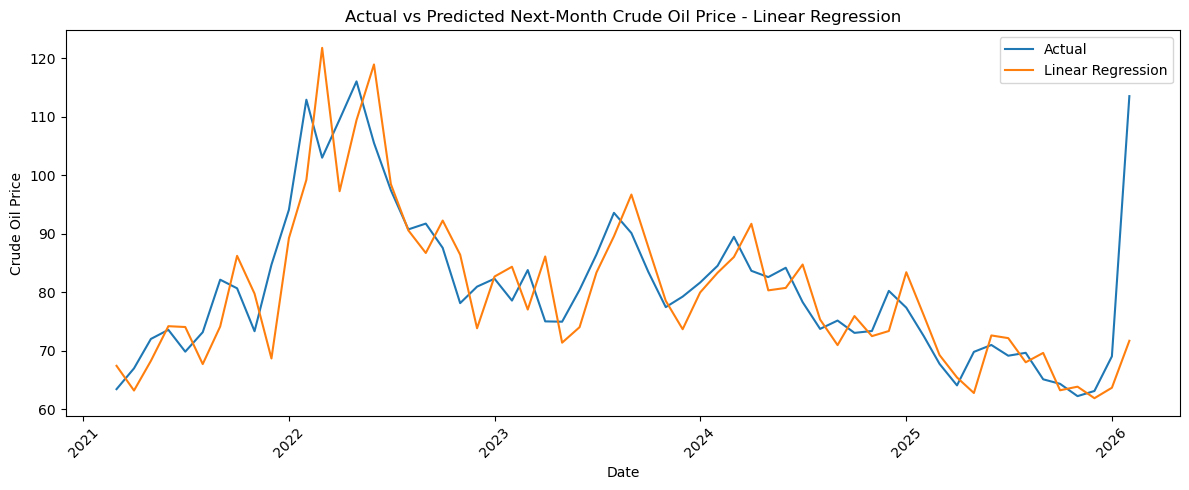

In [19]:
plt.figure(figsize=(12, 5))

plt.plot(
    test_df["date"],
    y_test.values,
    label="Actual"
)

plt.plot(
    test_df["date"],
    linear_pred,
    label="Linear Regression"
)

plt.title("Actual vs Predicted Next-Month Crude Oil Price - Linear Regression")
plt.xlabel("Date")
plt.ylabel("Crude Oil Price")
plt.legend()

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

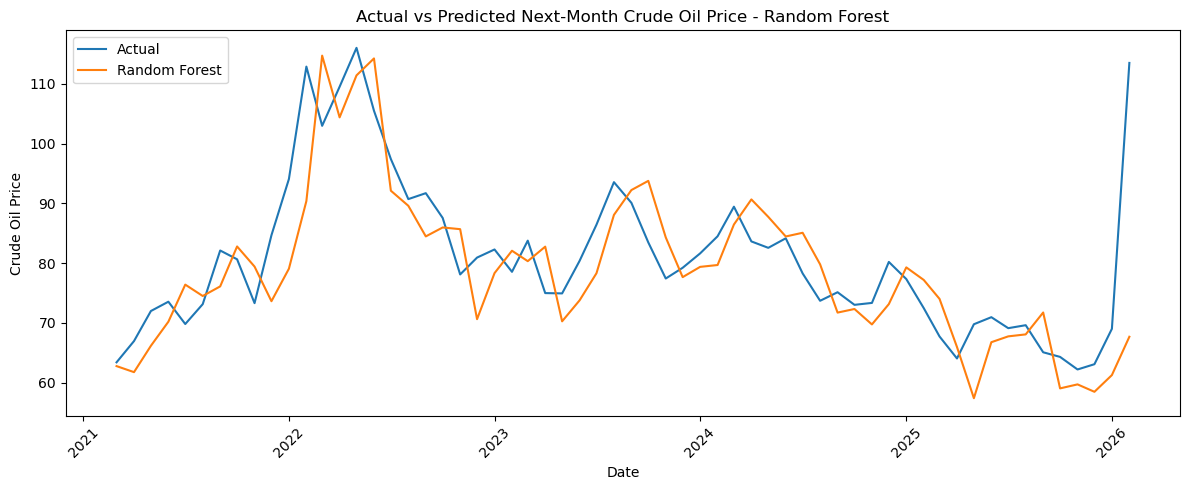

In [20]:
plt.figure(figsize=(12, 5))

plt.plot(
    test_df["date"],
    y_test.values,
    label="Actual"
)

plt.plot(
    test_df["date"],
    rf_pred,
    label="Random Forest"
)

plt.title("Actual vs Predicted Next-Month Crude Oil Price - Random Forest")
plt.xlabel("Date")
plt.ylabel("Crude Oil Price")
plt.legend()

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [21]:
feature_importance = pd.DataFrame({
    "feature": features,
    "importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "importance",
    ascending=False
)

display(feature_importance)

,feature,importance
4,crude_ma_3,0.700246
0,previous_crude_price,0.194359
5,crude_ma_6,0.018157
12,price_vs_ma_3,0.015755
6,crude_ma_12,0.014555
13,price_vs_ma_6,0.011997
10,momentum_3m,0.007132
14,price_vs_ma_12,0.006367
9,volatility_12m,0.005812
2,crude_return,0.005198


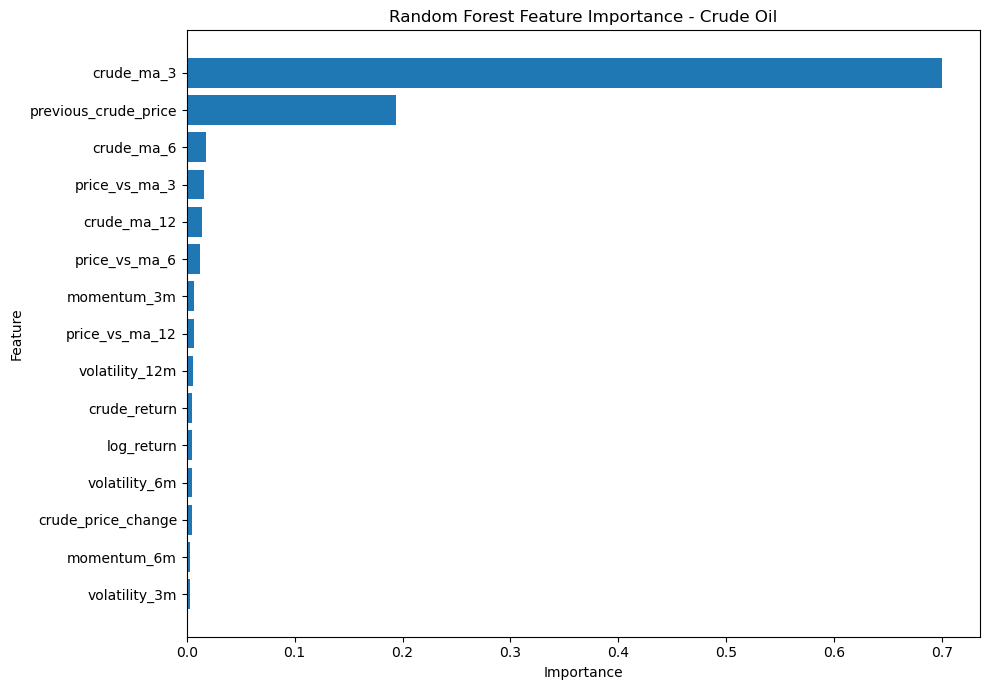

In [22]:
plt.figure(figsize=(10, 7))

plt.barh(
    feature_importance["feature"],
    feature_importance["importance"]
)

plt.gca().invert_yaxis()

plt.title("Random Forest Feature Importance - Crude Oil")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [23]:
importance_path = "../data/processed/indian_basket_crude_random_forest_feature_importance.csv"

feature_importance.to_csv(
    importance_path,
    index=False
)

print("Feature importance saved successfully.")
print(importance_path)

Feature importance saved successfully.
../data/processed/indian_basket_crude_random_forest_feature_importance.csv


In [24]:
predictions = pd.DataFrame({
    "date": test_df["date"],
    "actual_next_month_crude_price": y_test.values,
    "baseline_prediction": baseline_pred,
    "linear_regression_prediction": linear_pred,
    "random_forest_prediction": rf_pred
})

display(predictions.head(10))

,date,actual_next_month_crude_price,baseline_prediction,linear_regression_prediction,random_forest_prediction
239,2021-03-01,63.396977,64.463923,67.384787,62.766333
240,2021-04-01,66.953085,64.463923,63.162358,61.755380
241,2021-05-01,71.982647,64.463923,68.235354,66.165144
242,2021-06-01,73.539061,64.463923,74.160454,70.191513
243,2021-07-01,69.804724,64.463923,74.019528,76.397827
244,2021-08-01,73.130738,64.463923,67.681765,74.496766
245,2021-09-01,82.107394,64.463923,74.112908,76.102317
246,2021-10-01,80.637301,64.463923,86.187546,82.782489
247,2021-11-01,73.298824,64.463923,79.717987,79.416086
248,2021-12-01,84.666319,64.463923,68.639857,73.622711


In [25]:
predictions_path = "../data/processed/indian_basket_crude_model_predictions.csv"

predictions.to_csv(
    predictions_path,
    index=False
)

print("Predictions saved successfully.")
print(predictions_path)

Predictions saved successfully.
../data/processed/indian_basket_crude_model_predictions.csv


In [26]:
print("=" * 60)
print("INDIAN BASKET CRUDE OIL INITIAL MODEL EXPERIMENT")
print("=" * 60)

print("\nDataset:")
print("Indian Basket Crude Oil")

print("\nTarget:")
print("Next-Month Crude Oil Price")

print("\nTraining samples:", len(train_df))
print("Testing samples:", len(test_df))

print("\nModel Performance:")
display(results)

print("\nExperiment completed successfully.")

INDIAN BASKET CRUDE OIL INITIAL MODEL EXPERIMENT

Dataset:
Indian Basket Crude Oil

Target:
Next-Month Crude Oil Price

Training samples: 239
Testing samples: 60

Model Performance:


,Model,MAE,RMSE
0,Baseline,16.537258,20.799292
1,Linear Regression,5.610043,8.268037
2,Random Forest,6.178303,8.902505



Experiment completed successfully.
